In [ ]:
# coding: utf-8

# # Testes de modelagem - Otimização de Parametros Bayesiana

# # Pré-processamento dos dados

# In[1]:

import os
os.sys.path.insert(0,'/workspace/thommic/hot/pacotes_artfactory/')


# In[2]:

from hyperopt import hp, tpe, fmin, STATUS_OK, Trials
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np
import math


# In[157]:

pd.set_option('display.max_rows', 500)


# ### --- A partir daqui, pular para a importação do .csv com os dados pré processados

# In[185]:

df = pd.read_csv('leads_origin_agiliza.csv', delimiter=';')
df


# In[186]:

df.columns = map(str.upper, df.columns)
df = df.rename(columns={'PAGO': 'DS_STATUS', 'ESCORE_BVS_42': 'GH_BVS', 'GH_AVG':'GH_AVG_PROSPEC', 'ESCORE_C2B':'GH_C2BA'})


# In[187]:

df['QUALIFICADORA_PERIODO_COMPRA'].value_counts()


# In[188]:

qualific = {'LESS_THAN_THIRTY_DAYS':322,
            'MORE_THAN_THIRTY_DAYS':279,     
            'NOT_KNOW':5458,               
            'THIS_WEEK':6506,
            'FIFTEEN_DAYS':1727,
            'THIRTY_DAYS':1702,
            'TWO_DAYS':15
               }
df['QUALIFICADORA_PERIODO_COMPRA'] =  df['QUALIFICADORA_PERIODO_COMPRA'].str.upper().map(qualific)


# In[189]:

df['CLIENTE_DISPOSITIVO_ACESSO_MODELO'].value_counts()


# In[190]:

disp_doc = {'android':7008, 'ios':3321, 'windows':17636, '606560':0, 'linux':93}
df['CLIENTE_DISPOSITIVO_ACESSO_MODELO'] =  df['CLIENTE_DISPOSITIVO_ACESSO_MODELO'].str.lower().map(disp_doc)

seg_dic = {'AGÊNCIA':1,
             'UNICLASS':2,
          'PERSONNALITE':3}
df['ULTIMO_LEAD_CLIENTE_SEGMENTO'] =  df['ULTIMO_LEAD_CLIENTE_SEGMENTO'].map(seg_dic)

subpop_doc = {'NOT':1, 'NED':1, "NDT":1, "NCT":1, 'NBC':1, 'COT':2, 'CED':3, 'CDT':4,'CCL':5,"CCT":6 }
df['SUBPOP_AVG'] =  df['SUBPOP_AVG'].map(subpop_doc)

import numpy as np
conditions_itcv = [
    (df['GH_BVS'] < 237),
    (df['GH_BVS'] >= 237) & (df['GH_BVS'] < 350),
    (df['GH_BVS'] >= 350) & (df['GH_BVS'] < 501),
    (df['GH_BVS'] >= 501) & (df['GH_BVS'] < 740),
    (df['GH_BVS'] >= 740)]
choices = [1,2,3,4,5]
df['GH_BVS'] = np.select(conditions_itcv, choices, default=0)

df["DS_SEGMENTO"].replace({"AGÔøΩNCIA": "AGÊNCIA"}, inplace=True)
df["DS_SEGMENTO"].replace({"AGÊNCIA": "1", "UNICLASS": "2", "PERSONNALITE": "3"}, inplace=True)

mail_abandono = {True:1, False:0}
df['ENVIO_CRM_TRIGGER_EMAIL_ABANDONO'] =  df['ENVIO_CRM_TRIGGER_EMAIL_ABANDONO'].map(mail_abandono)


# In[191]:

import datetime as dt
df['FIRST_INTER'] = df['FIRST_INTER'].apply(lambda x: str(x))
df['FIRST_INTER'] = df['FIRST_INTER'].apply(lambda x: (x[6:10] + '-' + x[3:5] + '-' + x[0:2] + x[10:16] + ':00.000000') 
                                            if len(x) == 16 else x)
df['FIRST_INTER'] = df['FIRST_INTER'].apply(pd.to_datetime, format='%Y-%m-%d %H:%M:%S.%f')

df['DATA_PROSPECCAO'] = df['DT_PROSPECCAO'].apply(pd.to_datetime, format='%d%b%y:%H:%M:%S')

df['DAYS_prospec'] = (df['DATA_PROSPECCAO'] - df['FIRST_INTER']).dt.days
df['DAYS_prospec'].fillna(-1, inplace=True)


# In[192]:

ult_canal_series = df['ULTIMO_CANAL_ACESSADO'].value_counts()
zip_iterator = zip(ult_canal_series.index, ult_canal_series)
ult_canal = dict(zip_iterator)
df['ULTIMO_CANAL_ACESSADO'] =  df['ULTIMO_CANAL_ACESSADO'].map(ult_canal)


# In[193]:

ult_canal_series = df['ULTIMO_CANAL_ACESSADO'].value_counts()
zip_iterator = zip(ult_canal_series.index, ult_canal_series)
ult_canal = dict(zip_iterator)
df['ULTIMO_CANAL_ACESSADO'] =  df['ULTIMO_CANAL_ACESSADO'].map(ult_canal)

prim_canal_series = df['PRIMEIRO_CANAL_ACESSADO'].value_counts()
zip_iterator = zip(prim_canal_series.index, prim_canal_series)
prim_canal = dict(zip_iterator)
df['PRIMEIRO_CANAL_ACESSADO'] =  df['PRIMEIRO_CANAL_ACESSADO'].map(prim_canal)

regiao_uf_series = df['REGIAO_UF'].value_counts()
zip_iterator = zip(regiao_uf_series.index, regiao_uf_series)
regiao_uf = dict(zip_iterator)
df['REGIAO_UF'] =  df['REGIAO_UF'].map(regiao_uf)

tipo_canal  = {'DIGITAL_ASSISTANT_CLIENT' : 1 , 'DIGITAL_ASSISTANT_DEALER' :2 , 'DIGITAL_ASSISTANT_DEALER_V2':3 }
df['TIPO_CANAL'] =  df['TIPO_CANAL'].map(tipo_canal)

df['ANALISE_CREDITO_APROVADO'] = df['FEZ_ANALISE_CREDITO'].apply(lambda x: 1 if x == 'APPROVED' else 0)

df["FEZ_ANALISE_CREDITO"].fillna(0, inplace=True)
df['FEZ_ANALISE_CREDITO'] = df['FEZ_ANALISE_CREDITO'].apply(lambda x: 1 if x != 0 else 0)

df["ULTIMO_LEAD_QTD_PARCELA"].fillna(0, inplace=True)
df["GH_C2BA"].fillna(0, inplace=True)
df["TIPO_CANAL"].fillna(0, inplace=True)
df["REGIAO_UF"].fillna(0, inplace=True)
df["ULTIMO_CANAL_ACESSADO"].fillna(0, inplace=True)
df["PRIMEIRO_CANAL_ACESSADO"].fillna(0, inplace=True)
df["CLIENTE_RENDA_QTD_SALARIO_MINIMO"].fillna(0, inplace=True)
df["PRE_ANALISIS_GH"].fillna(0, inplace=True)
df["PRE_ANALISIS_GP"].fillna(0, inplace=True)
df["PRE_ANALISIS_MAX_PARCELA_VALOR"].fillna(0, inplace=True)
df["PRE_ANALISIS_PRE_ANALISADO"].fillna(-1, inplace=True)
df["PRE_ANALISIS_RECUSA_OP"].fillna(0, inplace=True)
df["ENVIO_CRM_TRIGGER_EMAIL_ABANDONO"].fillna(-1, inplace=True)
df["GH_BVS"].fillna(0, inplace=True)
df['DS_SEGMENTO']=df['DS_SEGMENTO'].apply(pd.to_numeric, errors='coerce').fillna(0)
df["CLIENTE_EMAIL_CONTAINS_NOME"].fillna(-1, inplace=True)
df["CLIENTE_EMAIL_CONTAINS_UPPERCASE"].fillna(-1, inplace=True)
df["CLIENTE_EMAIL_DOMINIO_PULBICO"].fillna(-1, inplace=True)
df["ULTIMO_LEAD_PORCENTAGEM_ENTRADA"].fillna(0, inplace=True)
df["ULTIMO_LEAD_VALOR_PARCELA"].fillna(0, inplace=True)
df["ULTIMO_LEAD_VALOR_VEICULO"].fillna(0, inplace=True)
df["ULTIMO_LEAD_VEICULO_ANO"].fillna(0, inplace=True)
df["DS_STATUS"].fillna(0, inplace=True)
df["LIMITE_VCL"].fillna(0, inplace=True)
df["LIMITE_VCL_ITCV_MONT_CV"].fillna(0, inplace=True)
df["LIMITE_VCL_REDE_MONT_CV"].fillna(0, inplace=True)
df["GH_C2BA"].fillna(0, inplace=True)
df["QUALIFICADORA_PERIODO_COMPRA"].fillna(0, inplace=True)
df["CLIENTE_DISPOSITIVO_ACESSO_MODELO"].fillna(0, inplace=True)
df['ULTIMO_LEAD_CLIENTE_SEGMENTO'].fillna(0, inplace=True)
df["SUBPOP_AVG"].fillna(0, inplace=True)
df['GH_AVG_PROSPEC'].fillna(0, inplace=True)


# In[194]:

import bifrost
from bifrost import Hadoop

def pwd():
    with open('/workspace/thommic/password', 'r') as f:
        return f.read(6)

ghp = Hadoop('ghp00216', password=pwd())


# In[195]:

df_ecivil = ghp.query_fetchall(f'''

SELECT * 
FROM ghp00216.thommic_cpf_leads_ger_ecivil;

''')


# In[196]:

df_leads_ger = pd.merge(df, df_ecivil, left_on='CPF', right_on='num_cpf', how='inner')
df_leads_ger = df_leads_ger.rename(columns={'estado_civil': 'ESTADO_CIVIL'})
df_leads_ger["ESTADO_CIVIL"].fillna(0, inplace=True)
df_leads_ger = df_leads_ger.astype({'ESTADO_CIVIL': 'int32'})


# In[197]:

df_leads_ger.to_csv('MANAGER_LEADS_ORCHESTRATOR_TRAIN_DATA_PP_2TRIAL.csv', index=False)


# In[ ]:




# In[ ]:




# In[ ]:

df_leads_ger = pd.read_csv('MANAGER_LEADS_ORCHESTRATOR_TRAIN_DATA_PP_2TRIAL.csv', delimiter=';')
df_leads_ger


# In[200]:

y = df_leads_ger['DS_STATUS']

X = df_leads_ger[['CANAIS_COUNT','CLIENTE_DISPOSITIVO_ACESSO_MODELO','CLIENTE_EMAIL_CONTAINS_NOME',    'CLIENTE_EMAIL_CONTAINS_UPPERCASE',    'CLIENTE_EMAIL_DOMINIO_PULBICO',    'LEADS_COUNT',    'LIMITE_VCL',    'LIMITE_VCL_ITCV_MONT_CV',    'LIMITE_VCL_REDE_MONT_CV',    'QUALIFICADORA_PERIODO_COMPRA',    'ULTIMO_LEAD_CLIENTE_SEGMENTO',    'ULTIMO_LEAD_CLIENT_PREANALYSIS_CORRENTISTA',    'ULTIMO_LEAD_ENQUADRADO_PA_ITCV',    'ULTIMO_LEAD_ENQUADRADO_PA_REDE',    'ULTIMO_LEAD_ENQUADRADO_PA_REDE_MONTANTE',    'ULTIMO_LEAD_PORCENTAGEM_ENTRADA',    'ULTIMO_LEAD_VALOR_PARCELA',    'ULTIMO_LEAD_VALOR_VEICULO',    'ULTIMO_LEAD_VEICULO_ANO',    'ULTIMO_LEAD_VEICULO_ZERO_KM',    'GH_AVG_PROSPEC',    'SUBPOP_AVG',    'GH_C2BA',    'GH_BVS',    'DS_SEGMENTO',    'CLIENTE_RENDA_QTD_SALARIO_MINIMO',     'PRE_ANALISIS_GH',    'PRE_ANALISIS_GP',    'PRE_ANALISIS_MAX_PARCELA_VALOR',    'PRE_ANALISIS_PRE_ANALISADO',    'DAYS_prospec',    'HAS_EXTERNAL_PARAMS',    'ENVIO_CRM_TRIGGER',    'ENVIO_CRM_TRIGGER_EMAIL_ABANDONO',    'PRIMEIRO_CANAL_ACESSADO',    'REGIAO_UF',    'TIPO_CANAL',    'ULTIMO_CANAL_ACESSADO',    'ANALISE_CREDITO_APROVADO',    'ULTIMO_LEAD_QTD_PARCELA',    'ESTADO_CIVIL',    'FEZ_ANALISE_CREDITO'    ]]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
#X_train, X_test_calib, y_train, y_test_calib = train_test_split(X, y, test_size=0.4, stratify=y, random_state=42)
#X_test, X_calib, y_test, y_calib = train_test_split(X_test_calib, y_test_calib, test_size=0.4, stratify=y_test_calib, random_state=42)


# In[203]:

X_train.shape, X_test.shape


# In[204]:

y_train.shape, y_test.shape


# In[205]:

y_train.value_counts()


# In[206]:

y_test.value_counts()


# In[208]:

k_fold_split_hyper=5
max_evals_hyper=50
iter_no_change=50 
init_tpe = 15
semente_thomas=2020
rstate = np.random.RandomState(semente_thomas)
saving_path = 'modelo_orquestrador_gerenteV4-otimizacao_2trial'


# # XGBoost

# ## -Treinamento

# In[212]:

import xgboost as xgb


# In[224]:

#Função que vamos minimizar
def obj_fun_xgb(params):
    
    model = xgb.XGBClassifier(random_state = semente_thomas,**params)
    
    cv = StratifiedKFold(n_splits=k_fold_split_hyper, shuffle=True, random_state=semente_thomas) 
    
    scores = cross_val_score(model, X_train, y_train, scoring='recall', cv=cv)    
    
     # Extrai melhor escore
    best_score = np.mean(scores)
    
    # Perda deve ser minimizada!
    loss = 1 - best_score
    
    if loss < obj_fun_xgb.best_loss:
        obj_fun_xgb.best_loss = loss
        obj_fun_xgb.best_iter = obj_fun_xgb.iteracao + 1
    
    obj_fun_xgb.iteracao += 1
    print('---Iteracao ' + str(obj_fun_xgb.iteracao) + '---')
    print('   Melhor score iteracao: ' + str(best_score))
    print('   Parametros: ' + str(params))
    print('   Best so far: iteracao ' + str(obj_fun_xgb.best_iter) + ' (' + str(obj_fun_xgb.best_loss) + ')')
       
    return {'loss':loss, 'status': STATUS_OK, 'params': params}

obj_fun_xgb.iteracao = 0
obj_fun_xgb.best_loss = 1
obj_fun_xgb.best_iter = 0


# In[225]:

# Definindo espaço de busca de parametros
params_xgb = {
    'max_depth' : hp.choice('max_depth', range(3, 30, 1)),
    'learning_rate' : hp.quniform('learning_rate', 0.01, 0.5, 0.01),
    'n_estimators' : hp.choice('n_estimators', range(3, 205, 5)),
    'eval_metric': 'aucpr',
    'gamma' : hp.quniform('gamma', 0, 0.50, 0.01),
    'min_child_weight' : hp.quniform('min_child_weight', 1, 8, 1),
    'subsample' : hp.quniform('subsample', 0.1, 1, 0.01),
    'colsample_bytree' : hp.quniform('colsample_bytree', 0.1, 1.0, 0.01),
    'scale_pos_weight' : hp.choice('scale_pos_weight', [0.5, 0.6, 0.66, 0.75, 0.9, 1, 2, 3])
}


# In[ ]:

#Otimização
from functools import partial
algo = partial(tpe.suggest, n_startup_jobs=init_tpe)
trials_xgb = Trials()
best_xgb = fmin(obj_fun_xgb, params_xgb, algo=algo, max_evals=max_evals_hyper, trials=trials_xgb, rstate=rstate)


# In[50]:

import joblib
results = trials_xgb.results
results_df = pd.DataFrame({'loss': [x['loss'] for x in results], 
                           'params': [x['params'] for x in results]
                            })
results_df = results_df.sort_values('loss', ascending = True).reset_index()
results_df_dic = {'train_results' : results_df}
joblib.dump(results_df, 'train_res_xgboost_20V4ger.jblib')


# In[60]:

best_xgb = results_df['params'][0]
modelo_xgb=xgb.XGBClassifier(random_state = semente_thomas,**best_xgb)
modelo_xgb.fit(np.array(X_train), np.array(y_train))
joblib.dump(modelo_xgb, 'best_model_xgboost_20V4ger.jblib')


# In[86]:

cv = RepeatedStratifiedKFold(n_splits=k_fold_split_hyper, n_repeats=3, random_state=semente_thomas) 
modelo_xgb_calib = CalibratedClassifierCV(modelo_xgb, method='isotonic', cv='prefit')
modelo_xgb_calib.fit(np.array(X_test_calib), np.array(y_test_calib))
joblib.dump(modelo_xgb, 'best_model_xgboost_20V4ger_calib.jblib')


# ## - Predições e avaliação do modelo

# In[62]:

import joblib
modelo_xgb_calib = joblib.load('best_model_xgboost_20V4ger_calib.jblib')


# In[87]:

#XGBoost
y_pred_train_xg=modelo_xgb_calib.predict_proba(np.array(X_train))[:,1]
y_pred_test_xg=modelo_xgb_calib.predict_proba(np.array(X_test))[:,1]


# In[88]:

import seaborn as sns
import matplotlib.pyplot as plt     
from sklearn.metrics import classification_report,confusion_matrix
get_ipython().magic('matplotlib inline')

cm = confusion_matrix(y_test, modelo_xgb_calib.predict(np.array(X_test)))
ax= plt.subplot()
sns.heatmap(cm, annot=True, ax = ax, fmt = 'g', cmap="Blues"); #annot=True to annotate cells

# labels, title and ticks
ax.set_xlabel('Preditos');ax.set_ylabel('Reais'); 
ax.set_title('Matriz de Confusão'); 
ax.xaxis.set_ticklabels(['Não Pago', 'Pago']); 
ax.yaxis.set_ticklabels(['Não Pago', 'Pago']);

print(classification_report(y_test,modelo_xgb.predict(np.array(X_test))))


# In[73]:

import math
dic = {'y_test': y_test, 'y_pred': modelo_xgb.predict(np.array(X_test)),'y_pred_prob': modelo_xgb.predict_proba(np.array(X_test))[:, 1]}
df_xgboost_results = pd.DataFrame(data=dic)
bins = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]
labels = ['0 a 10', '10 a 20', '20 a 30', '30 a 40', '40 a 50', '50 a 60', '60 a 70', '70 a 80', '80 a 90', '90 a 100']
df_xgboost_results['faixa_score'] = pd.cut(df_xgboost_results['y_pred_prob'], bins=bins, labels=labels)
df_xgboost_results['score'] = df_xgboost_results.y_pred_prob.apply(lambda x: math.floor(x*100))

df_aval_xgboost = pd.concat([df_xgboost_results.groupby(['faixa_score']).count()[['y_test']], 
           df_xgboost_results.groupby(['faixa_score']).count()[['y_test']]/df_xgboost_results['y_test'].count(),
           df_xgboost_results.groupby(['faixa_score']).sum()[['y_test']],
           df_xgboost_results.groupby(['faixa_score']).sum()[['y_test']]/df_xgboost_results.groupby(['faixa_score']).count()[['y_test']],
           df_xgboost_results.groupby(['faixa_score']).count()[['y_test']] - df_xgboost_results.groupby(['faixa_score']).sum()[['y_test']],
           df_xgboost_results.groupby(['faixa_score']).sum()[['y_test']]/df_xgboost_results['y_test'].sum()], axis=1)

df_aval_xgboost.columns = ['leads','%(total)','pagos','conversão faixa','não pagos','conversão geral']

df_aval_xgboost['%(total)'] = pd.Series(["{0:.2f}%".format(val * 100) for val in df_aval_xgboost['%(total)']], index = df_aval_xgboost.index)
df_aval_xgboost['pagos'] = pd.Series(["{0:.0f}".format(val) for val in df_aval_xgboost['pagos']], index = df_aval_xgboost.index)
df_aval_xgboost['conversão faixa'] = pd.Series(["{0:.2f}%".format(val * 100) for val in df_aval_xgboost['conversão faixa']], index = df_aval_xgboost.index)
df_aval_xgboost['não pagos'] = pd.Series(["{0:.0f}".format(val) for val in df_aval_xgboost['não pagos']], index = df_aval_xgboost.index)
df_aval_xgboost['conversão geral'] = pd.Series(["{0:.2f}%".format(val * 100) for val in df_aval_xgboost['conversão geral']], index = df_aval_xgboost.index)
df_aval_xgboost


# In[74]:

import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(data=df_xgboost_results[df_xgboost_results['y_test'] == 1], x="y_pred_prob", color="red", label="Pagos")
sns.histplot(data=df_xgboost_results[df_xgboost_results['y_test'] == 0], x="y_pred_prob", color="skyblue", label="Não Pagos")

plt.legend() 
plt.show()


# In[68]:

g = sns.catplot(x="score", hue="y_test", kind="count", 
            palette="bright", edgecolor=".6", aspect = 3,
            data=df_xgboost_results)

g.ax.set_xticks([0,10,20,30,40,50,60,70,80,90,100])
g.set_xticklabels([0,10,20,30,40,50,60,70,80,90,100])
g.set_axis_labels("SCORE", "")
g.legend.get_texts()[0].set_text('Não pago')
g.legend.get_texts()[1].set_text('Pago')
g.legend.get_title().set_text('')


# ## - Feature Importances

# In[69]:

modelo_xgb.feature_importances_


# In[70]:

import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

# sorted(zip(clf.feature_importances_, X.columns), reverse=True)
feature_imp = pd.DataFrame(sorted(zip(modelo_xgb.feature_importances_,X_train.columns)), columns=['Value','Feature'])

plt.figure(figsize=(20, 10))
sns.barplot(x="Value", y="Feature", data=feature_imp.sort_values(by="Value", ascending=False))
plt.title('XGBoost Features (avg over folds)')
plt.tight_layout()
plt.show()
plt.savefig('xgboost_importances-01.png')


# # LGBM: goss boosting

# ## - Treinamento

# In[89]:

import lightgbm as lgbm


# In[211]:

#Função que vamos minimizar
def obj_fun_lgbm_goss(params):
    model = lgbm.LGBMClassifier(random_state = semente_thomas,**params)
    
    cv = StratifiedKFold(n_splits=k_fold_split_hyper, shuffle = True, random_state=semente_thomas) 
    
    scores = cross_val_score(model, X_train, y_train, scoring='roc_auc', cv=cv)    
    
    # Extrai melhor escore
    best_score = np.mean(scores)
    
    # Perda deve ser minimizada!
    loss = 1 - best_score
    
    if loss < obj_fun_lgbm_goss.best_loss:
        obj_fun_lgbm_goss.best_loss = loss
        obj_fun_lgbm_goss.best_iter = obj_fun_lgbm_goss.iteracao + 1
    
    obj_fun_lgbm_goss.iteracao += 1
    print('---Iteracao ' + str(obj_fun_lgbm_goss.iteracao) + '---')
    print('   Melhor score iteracao: ' + str(best_score))
    print('   Parâmetros: ' + str(params))
    print('   Best so far: iteracao ' + str(obj_fun_lgbm_goss.best_iter) + ' (' + str(obj_fun_lgbm_goss.best_loss) + ')')
       
    return {'loss':loss, 'status': STATUS_OK, 'params': params}
obj_fun_lgbm_goss.iteracao = 0
obj_fun_lgbm_goss.best_loss = 1
obj_fun_lgbm_goss.best_iter = 0


# In[212]:

# Definindo espaço de busca de parametros
params_lgbm_goss = {
    'objective' : 'binary',
    'boosting_type' : 'goss',
    'num_leaves' : hp.choice('num_leaves', [5, 10, 50, 100]),
    'max_depth' : hp.choice('max_depth', [-1, 5, 10, 25]),
    'learning_rate': hp.loguniform('learning_rate', np.log(0.01), np.log(0.5)),
#   'n_estimators' : hp.choice('n_estimators', [50, 100, 250, 500, 750, 1000]),
#   'subsample_for_bin' : 
    'scale_pos_weight' : hp.choice('scale_pos_weight', [0.5, 0.66, 1, 3, 5]), 
#   'min_split_gain' : 
    'min_child_weight': hp.uniform('min_child_weight', 0.5, 10),
    'min_child_samples' : hp.choice('min_child_samples', range(5, 51, 5)),
#   'subsample' : hp.uniform('subsample', 0, 1),
#   'subsample_freq' : hp.choice('subsample_freq', range(0, 10, 1)),
    'colsample_bytree' : hp.uniform('colsample_by_tree', 0.3, 0.8),
    'reg_alpha': hp.choice('reg_alpha', [0.1, 1, 5, 10]),
    'reg_lambda': hp.choice('reg_lambda', [0.1, 1, 5, 10])
}


# In[ ]:

#Otimização
trials_lgbm_goss = Trials()
best_lgbm_goss = fmin(obj_fun_lgbm_goss, params_lgbm_goss, algo=tpe.suggest, max_evals=max_evals_hyper, trials=trials_lgbm_goss, rstate=rstate, verbose=False)


# In[148]:

import joblib
results = trials_lgbm_goss.results
results_df = pd.DataFrame({'loss': [x['loss'] for x in results], 
                           'params': [x['params'] for x in results]
                            })
results_df = results_df.sort_values('loss', ascending = True).reset_index()
results_df_dic = {'train_results' : results_df}
joblib.dump(results_df, 'train_res_lgbmgoss_20V4ger.jblib')


# In[ ]:

best_lgbm_goss = results_df['params'][0]
modelo_lgbm_goss=lgbm.LGBMClassifier(random_state = semente_thomas,**best_lgbm_goss)
modelo_lgbm_goss.fit(X_train, y_train)
joblib.dump(modelo_lgbm_goss, 'best_model_lgbmgoss_20V4ger.jblib')


# In[ ]:

cv = RepeatedStratifiedKFold(n_splits=k_fold_split_hyper, n_repeats=3, random_state=semente_thomas) 
modelo_lgbm_goss_calib = CalibratedClassifierCV(base_estimator=modelo_lgbm_goss, method='isotonic', cv='prefit')
modelo_lgbm_goss_calib.fit(X_calib, y_calib)
joblib.dump(modelo_lgbm_goss_calib, 'best_model_lgbmgoss_20V4ger_calib.jblib')


# In[83]:

cv = RepeatedStratifiedKFold(n_splits=k_fold_split_hyper, n_repeats=3, random_state=semente_thomas) 
modelo_lgbm_goss_calib = CalibratedClassifierCV(base_estimator=modelo_lgbm_goss, method='isotonic', cv='prefit')
modelo_lgbm_goss_calib.fit(X_calib, y_calib)
joblib.dump(modelo_lgbm_goss_calib, 'best_model_lgbmgoss_20V4ger_calib.jblib')


# ## - Predições e avaliação do modelo

# In[ ]:

import joblib
modelo_lgbm_goss = joblib.load('best_model_lgbmgoss_20V4ger_calib.jblib')


# In[84]:

y_pred_train_lgbm_goss=modelo_lgbm_goss.predict_proba(X_train)[:,1]
y_pred_test_lgbm_goss=modelo_lgbm_goss.predict_proba(X_test)[:,1]


# In[85]:

import seaborn as sns
import matplotlib.pyplot as plt     
from sklearn.metrics import classification_report,confusion_matrix
get_ipython().magic('matplotlib inline')

print(classification_report(y_test,modelo_lgbm_goss.predict(X_test)))

cm = confusion_matrix(y_test, modelo_lgbm_goss.predict(X_test))
ax= plt.subplot()
sns.heatmap(cm, annot=True, ax = ax, fmt = 'g', cmap="Blues"); #annot=True to annotate cells

# labels, title and ticks
ax.set_xlabel('Preditos');ax.set_ylabel('Reais'); 
ax.set_title('Matriz de Confusão'); 
ax.xaxis.set_ticklabels(['Não Pago', 'Pago']); ax.yaxis.set_ticklabels(['Não Pago', 'Pago']);


# In[109]:

import math
dic = {'y_test': y_test, 'y_pred': modelo_lgbm.predict(X_test), 'y_pred_prob': modelo_lgbm.predict_proba(X_test)[:, 1]}
df_lgbm_results = pd.DataFrame(data=dic)
bins = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]
labels = ['0 a 10', '10 a 20', '20 a 30', '30 a 40', '40 a 50', '50 a 60', '60 a 70', '70 a 80', '80 a 90', '90 a 100']
df_lgbm_results['faixa_score'] = pd.cut(df_lgbm_results['y_pred_prob'], bins=bins, labels=labels)
df_lgbm_results['score'] = df_lgbm_results.y_pred_prob.apply(lambda x: math.floor(x*100))

df_aval_lgbm = pd.concat([df_lgbm_results.groupby(['faixa_score']).count()[['y_test']], 
           df_lgbm_results.groupby(['faixa_score']).count()[['y_test']]/df_lgbm_results['y_test'].count(),
           df_lgbm_results.groupby(['faixa_score']).sum()[['y_test']],
           df_lgbm_results.groupby(['faixa_score']).sum()[['y_test']]/df_lgbm_results.groupby(['faixa_score']).count()[['y_test']],
           df_lgbm_results.groupby(['faixa_score']).count()[['y_test']] - df_lgbm_results.groupby(['faixa_score']).sum()[['y_test']],
           df_lgbm_results.groupby(['faixa_score']).sum()[['y_test']]/df_lgbm_results['y_test'].sum()], axis=1)

df_aval_lgbm.columns = ['leads','%(total)','pagos','conversão faixa','não pagos','conversão geral']

df_aval_lgbm['%(total)'] = pd.Series(["{0:.2f}%".format(val * 100) for val in df_aval_lgbm['%(total)']], index = df_aval_lgbm.index)
df_aval_lgbm['pagos'] = pd.Series(["{0:.0f}".format(val) for val in df_aval_lgbm['pagos']], index = df_aval_lgbm.index)
df_aval_lgbm['conversão faixa'] = pd.Series(["{0:.2f}%".format(val * 100) for val in df_aval_lgbm['conversão faixa']], index = df_aval_lgbm.index)
df_aval_lgbm['não pagos'] = pd.Series(["{0:.0f}".format(val) for val in df_aval_lgbm['não pagos']], index = df_aval_lgbm.index)
df_aval_lgbm['conversão geral'] = pd.Series(["{0:.2f}%".format(val * 100) for val in df_aval_lgbm['conversão geral']], index = df_aval_lgbm.index)
df_aval_lgbm


# In[110]:

import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(data=df_lgbm_results[df_lgbm_results['y_test'] == 1], x="y_pred_prob", color="red", label="Pagos")
sns.histplot(data=df_lgbm_results[df_lgbm_results['y_test'] == 0], x="y_pred_prob", color="skyblue", label="Não Pagos")

plt.legend() 
plt.show()


# In[111]:

sns.catplot(x="score", hue="y_test", kind="count",
            palette="bright", edgecolor=".6", aspect = 3,
            data=df_lgbm_results)


# ## - Feature Importances

# In[112]:

modelo_lgbm.feature_importances_


# In[113]:

import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

# sorted(zip(clf.feature_importances_, X.columns), reverse=True)
feature_imp = pd.DataFrame(sorted(zip(modelo_lgbm.feature_importances_,X_train.columns)), columns=['Value','Feature'])

plt.figure(figsize=(20, 10))
sns.barplot(x="Value", y="Feature", data=feature_imp.sort_values(by="Value", ascending=False))
plt.title('LGBM (goss) Features (avg over folds)')
plt.tight_layout()
plt.show()
plt.savefig('lgbm_goss_importances-01.png')


# # LGBM: gbdt boosting

# ## - Treinamento

# In[96]:

import lightgbm as lgbm


# In[98]:

#Função que vamos minimizar
def obj_fun_lgbm_gbdt(params):    
    model = lgbm.LGBMClassifier(random_state = semente_thomas,**params)
    
    cv = StratifiedKFold(n_splits=k_fold_split_hyper, n_repeats=3, random_state=semente_thomas) 
    
    scores = cross_val_score(calibrated, X_train, y_train, scoring='roc_auc', cv=cv)    
    
    # Extrai melhor escore
    best_score = np.mean(scores)
    
    # Perda deve ser minimizada!
    loss = 1 - best_score
    
    if loss < obj_fun_lgbm_gbdt.best_loss:
        obj_fun_lgbm_gbdt.best_loss = loss
        obj_fun_lgbm_gbdt.best_iter = obj_fun_lgbm_gbdt.iteracao + 1
    
    obj_fun_lgbm_gbdt.iteracao += 1
    print('---Iteracao ' + str(obj_fun_lgbm_gbdt.iteracao) + '---')
    print('   Melhor score iteracao: ' + str(best_score))
    print('   Parâmetros: ' + str(params))
    print('   Best so far: iteracao ' + str(obj_fun_lgbm_gbdt.best_iter) + ' (' + str(obj_fun_lgbm_gbdt.best_loss) + ')')
       
    return {'loss':loss, 'status': STATUS_OK, 'params': params}

obj_fun_lgbm_gbdt.iteracao = 0
obj_fun_lgbm_gbdt.best_loss = 1
obj_fun_lgbm_gbdt.best_iter = 0


# In[99]:

params_lgbm_gbdt = {
        'objective' : 'binary',
#        'boosting_type' : 'goss',
        'num_leaves' : hp.choice('num_leaves', [5, 10, 50, 100]),
        'max_depth' : hp.choice('max_depth', [-1, 5, 10, 25]),
        'learning_rate': hp.loguniform('learning_rate', np.log(0.01), np.log(0.5)),
#        'n_estimators' : hp.choice('n_estimators', [50, 100, 250, 500, 750, 1000]),
#        'subsample_for_bin' : 
        'scale_pos_weight' : hp.choice('scale_pos_weight', [0.5, 0.66, 1, 3, 5]), 
#        'min_split_gain' : 
        'min_child_weight': hp.uniform('min_child_weight', 0.5, 10),
        'min_child_samples' : hp.choice('min_child_samples', range(5, 51, 5)),
        'subsample' : hp.uniform('subsample', 0.1, 1),
        'subsample_freq' : hp.choice('subsample_freq', range(0, 11, 1)),
        'colsample_bytree' : hp.uniform('colsample_by_tree', 0.6, 1.0),
        'reg_alpha': hp.choice('reg_alpha', [0.1, 1, 2, 5, 7, 10]),
        'reg_lambda': hp.choice('reg_lambda', [0.1, 1, 2, 5, 7, 10])
    }


# In[ ]:

#Otimização
trials_lgbm_gbdt = Trials()
best_lgbm_gbdt = fmin(obj_fun_lgbm_gbdt, params_lgbm_gbdt, algo=tpe.suggest, max_evals=max_evals_hyper, trials=trials_lgbm_gbdt, rstate=rstate)


# In[ ]:

import joblib
results = trials_lgbm_gbdt.results
results_df = pd.DataFrame({'loss': [x['loss'] for x in results], 
                           'params': [x['params'] for x in results]
                            })
results_df = results_df.sort_values('loss', ascending = True).reset_index()
results_df_dic = {'train_results' : results_df}
joblib.dump(results_df, 'train_res_lgbmgbdt_20V4ger.jblib')


# In[ ]:

best_lgbm_gbdt = results_df['params'][0]
modelo_lgbm_gbdt=lgbm.LGBMClassifier(random_state = semente_thomas,**best_lgbm_gbdt)
modelo_lgbm_gbdt.fit(X_train, y_train)
joblib.dump(modelo_lgbm_gbdt, 'best_model_lgbmgbdt_20V4ger.jblib')


# In[ ]:

cv = RepeatedStratifiedKFold(n_splits=k_fold_split_hyper, n_repeats=3, random_state=semente_thomas) 
modelo_lgbm_gbdt_calib = CalibratedClassifierCV(base_estimator=modelo_lgbm_gbdt, method='isotonic', cv='prefit')
modelo_lgbm_gbdt_calib.fit(X_calib, y_calib)
joblib.dump(modelo_lgbm_gbdt_calib, 'best_model_lgbmgbdt_20V4ger_calib.jblib')


# ## - Predições e avaliação do modelo

# In[ ]:

import joblib
modelo_lgbm_gbdt = joblib.load('best_model_lgbmgbdt_20V4ger_calib.jblib')


# In[180]:

#XGBoost
y_pred_train_lgbm_gbdt=modelo_lgbm_gbdt.predict_proba(X_train)[:,1]
y_pred_test_lgbm_gbdt=modelo_lgbm_gbdt.predict_proba(X_test)[:,1]


# In[181]:

from sklearn.metrics import classification_report,confusion_matrix
print(confusion_matrix(y_test,modelo_lgbm_gbdt.predict(X_test)))
print(classification_report(y_test,modelo_lgbm_gbdt.predict(X_test)))


# In[182]:

import seaborn as sns
import matplotlib.pyplot as plt     
from sklearn.metrics import confusion_matrix
get_ipython().magic('matplotlib inline')

cm = confusion_matrix(y_test, modelo_lgbm_gbdt.predict(X_test))
ax= plt.subplot()
sns.heatmap(cm, annot=True, ax = ax, fmt = 'g', cmap="Blues"); #annot=True to annotate cells

# labels, title and ticks
ax.set_xlabel('Preditos');ax.set_ylabel('Reais'); 
ax.set_title('Matriz de Confusão'); 
ax.xaxis.set_ticklabels(['Não Pago', 'Pago']); ax.yaxis.set_ticklabels(['Não Pago', 'Pago']);


# In[183]:

import math
dic = {'y_test': y_test, 'y_pred': modelo_lgbm_gbdt.predict(X_test), 'y_pred_prob': modelo_lgbm_gbdt.predict_proba(X_test)[:, 1]}
df_lgbm_gbdt_results = pd.DataFrame(data=dic)
bins = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]
labels = ['0 a 10', '10 a 20', '20 a 30', '30 a 40', '40 a 50', '50 a 60', '60 a 70', '70 a 80', '80 a 90', '90 a 100']
df_lgbm_gbdt_results['faixa_score'] = pd.cut(df_lgbm_gbdt_results['y_pred_prob'], bins=bins, labels=labels)
df_lgbm_gbdt_results['score'] = df_lgbm_gbdt_results.y_pred_prob.apply(lambda x: math.floor(x*100))

df_aval_lgbm_gbdt = pd.concat([df_lgbm_gbdt_results.groupby(['faixa_score']).count()[['y_test']], 
           df_lgbm_gbdt_results.groupby(['faixa_score']).count()[['y_test']]/df_lgbm_gbdt_results['y_test'].count(),
           df_lgbm_gbdt_results.groupby(['faixa_score']).sum()[['y_test']],
           df_lgbm_gbdt_results.groupby(['faixa_score']).sum()[['y_test']]/df_lgbm_gbdt_results.groupby(['faixa_score']).count()[['y_test']],
           df_lgbm_gbdt_results.groupby(['faixa_score']).count()[['y_test']] - df_lgbm_gbdt_results.groupby(['faixa_score']).sum()[['y_test']],
           df_lgbm_gbdt_results.groupby(['faixa_score']).sum()[['y_test']]/df_lgbm_gbdt_results['y_test'].sum()], axis=1)

df_aval_lgbm_gbdt.columns = ['leads','%(total)','pagos','conversão faixa','não pagos','conversão geral']

df_aval_lgbm_gbdt['%(total)'] = pd.Series(["{0:.2f}%".format(val * 100) for val in df_aval_lgbm_gbdt['%(total)']], index = df_aval_lgbm_gbdt.index)
df_aval_lgbm_gbdt['pagos'] = pd.Series(["{0:.0f}".format(val) for val in df_aval_lgbm_gbdt['pagos']], index = df_aval_lgbm_gbdt.index)
df_aval_lgbm_gbdt['conversão faixa'] = pd.Series(["{0:.2f}%".format(val * 100) for val in df_aval_lgbm_gbdt['conversão faixa']], index = df_aval_lgbm_gbdt.index)
df_aval_lgbm_gbdt['não pagos'] = pd.Series(["{0:.0f}".format(val) for val in df_aval_lgbm_gbdt['não pagos']], index = df_aval_lgbm_gbdt.index)
df_aval_lgbm_gbdt['conversão geral'] = pd.Series(["{0:.2f}%".format(val * 100) for val in df_aval_lgbm_gbdt['conversão geral']], index = df_aval_lgbm_gbdt.index)
df_aval_lgbm_gbdt


# In[184]:

import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(data=df_lgbm_gbdt_results[df_lgbm_gbdt_results['y_test'] == 1], x="y_pred_prob", color="red", label="Pagos")
sns.histplot(data=df_lgbm_gbdt_results[df_lgbm_gbdt_results['y_test'] == 0], x="y_pred_prob", color="skyblue", label="Não Pagos")

plt.legend() 
plt.show()


# In[185]:

sns.catplot(x="score", hue="y_test", kind="count",
            palette="bright", edgecolor=".6", aspect = 3,
            data=df_lgbm_gbdt_results)


# ## - Feature Importances

# In[186]:

modelo_lgbm_gbdt.feature_importances_


# In[187]:

import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

# sorted(zip(clf.feature_importances_, X.columns), reverse=True)
feature_imp = pd.DataFrame(sorted(zip(modelo_lgbm_gbdt.feature_importances_,X_train.columns)), columns=['Value','Feature'])

plt.figure(figsize=(20, 10))
sns.barplot(x="Value", y="Feature", data=feature_imp.sort_values(by="Value", ascending=False))
plt.title('LGBM (gbdt) Features (avg over folds)')
plt.tight_layout()
plt.show()
plt.savefig('lgbm_gbdt_importances-01.png')


# In[ ]:




# # GBM

# ## - Treinamento

# In[39]:

from sklearn.ensemble import GradientBoostingClassifier as gbc


# In[49]:

#Função que vamos minimizar
def obj_fun_gbm(params):
    model = gbc(random_state = semente_thomas,**params)
    
    cv = RepeatedStratifiedKFold(n_splits=k_fold_split_hyper, n_repeats=3, random_state=semente_thomas) 
    
    calibrated = CalibratedClassifierCV(model, method='isotonic', cv=3)
    
    scores = cross_val_score(calibrated, X_train, y_train, scoring='roc_auc', cv=cv)    
    
    # Extrai melhor escore
    best_score = np.mean(scores)
    
    # Perda deve ser minimizada!
    loss = 1 - best_score
    
    if loss < obj_fun_gbm.best_loss:
        obj_fun_gbm.best_loss = loss
        obj_fun_gbm.best_iter = obj_fun_gbm.iteracao + 1
    
    obj_fun_gbm.iteracao += 1
    print('---Iteracao ' + str(obj_fun_gbm.iteracao) + '---')
    print('   Melhor score iteracao: ' + str(best_score))
    print('   Parametros: ' + str(params))
    print('   Best so far: iteracao ' + str(obj_fun_gbm.best_iter) + ' (' + str(obj_fun_gbm.best_loss) + ')')
       
    return {'loss':loss, 'status': STATUS_OK, 'params': params}

obj_fun_gbm.iteracao = 0
obj_fun_gbm.best_loss = 1
obj_fun_gbm.best_iter = 0


# In[50]:

params_gbm = {
    'max_depth': hp.choice('max_depth', range(6,30)),
    'n_estimators': hp.choice('n_estimators', range(2,100)),
    'learning_rate': hp.uniform('learning_rate', 0.01, 1),
    'min_samples_split': hp.uniform('min_samples_split', 0.1, 1),
    'min_samples_leaf': hp.uniform('min_samples_leaf', 0, 0.5)
}


# In[51]:

#Otimização
trials_gbm = Trials()
best_gbm = fmin(obj_fun_gbm, params_gbm, algo=tpe.suggest, max_evals=max_evals_hyper, trials=trials_gbm, rstate=rstate)


# In[ ]:

import joblib
results = trials_gbm.results
results_df = pd.DataFrame({'loss': [x['loss'] for x in results], 
                           'params': [x['params'] for x in results]
                            })
results_df = results_df.sort_values('loss', ascending = True).reset_index()
results_df_dic = {'train_results' : results_df}
joblib.dump(results_df, 'train_res_gbm_20V4ger.jblib')


# In[ ]:

best_gbm = results_df['params'][0]
modelo_gbm=gbc(random_state = semente_thomas,**best_gbm)
modelo_gbm.fit(X_train, y_train)
joblib.dump(modelo_gbm, 'best_model_gbm_20V4ger.jblib')


# In[ ]:

cv = RepeatedStratifiedKFold(n_splits=k_fold_split_hyper, n_repeats=3, random_state=semente_thomas) 
modelo_gbm_calib = CalibratedClassifierCV(base_estimator=modelo_gbm, method='isotonic', cv='prefit')
modelo_gbm_calib.fit(X_calib, y_calib)
joblib.dump(modelo_gbm_calib, 'best_model_gbm_20V4ger_calib.jblib')


# ## - Predições e avaliação do modelo

# In[ ]:

import joblib
modelo_gbm = joblib.load('best_model_gbm_20V4ger_calib.jblib')


# In[180]:

#XGBoost
y_pred_train_gbm=modelo_gbm.predict_proba(X_train)[:,1]
y_pred_test_gbm=modelo_gbm.predict_proba(X_test)[:,1]


# In[181]:

from sklearn.metrics import classification_report,confusion_matrix
print(confusion_matrix(y_test,modelo_gbm.predict(X_test)))
print(classification_report(y_test,modelo_gbm.predict(X_test)))


# In[182]:

import seaborn as sns
import matplotlib.pyplot as plt     
from sklearn.metrics import confusion_matrix
get_ipython().magic('matplotlib inline')

cm = confusion_matrix(y_test, modelo_gbm.predict(X_test))
ax= plt.subplot()
sns.heatmap(cm, annot=True, ax = ax, fmt = 'g', cmap="Blues"); #annot=True to annotate cells

# labels, title and ticks
ax.set_xlabel('Preditos');ax.set_ylabel('Reais'); 
ax.set_title('Matriz de Confusão'); 
ax.xaxis.set_ticklabels(['Não Pago', 'Pago']); ax.yaxis.set_ticklabels(['Não Pago', 'Pago']);


# In[183]:

import math
dic = {'y_test': y_test, 'y_pred': modelo_gbm.predict(X_test), 'y_pred_prob': modelo_gbm.predict_proba(X_test)[:, 1]}
df_gbm_results = pd.DataFrame(data=dic)
bins = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]
labels = ['0 a 10', '10 a 20', '20 a 30', '30 a 40', '40 a 50', '50 a 60', '60 a 70', '70 a 80', '80 a 90', '90 a 100']
df_gbm_results['faixa_score'] = pd.cut(df_gbm_results['y_pred_prob'], bins=bins, labels=labels)
df_gbm_results['score'] = df_gbm_results.y_pred_prob.apply(lambda x: math.floor(x*100))

df_aval_gbm = pd.concat([df_gbm_results.groupby(['faixa_score']).count()[['y_test']], 
           df_gbm_results.groupby(['faixa_score']).count()[['y_test']]/df_gbm_results['y_test'].count(),
           df_gbm_results.groupby(['faixa_score']).sum()[['y_test']],
           df_gbm_results.groupby(['faixa_score']).sum()[['y_test']]/df_gbm_results.groupby(['faixa_score']).count()[['y_test']],
           df_gbm_results.groupby(['faixa_score']).count()[['y_test']] - df_gbm_results.groupby(['faixa_score']).sum()[['y_test']],
           df_gbm_results.groupby(['faixa_score']).sum()[['y_test']]/df_gbm_results['y_test'].sum()], axis=1)

df_aval_gbm.columns = ['leads','%(total)','pagos','conversão faixa','não pagos','conversão geral']

df_aval_gbm['%(total)'] = pd.Series(["{0:.2f}%".format(val * 100) for val in df_aval_gbm['%(total)']], index = df_aval_gbm.index)
df_aval_gbm['pagos'] = pd.Series(["{0:.0f}".format(val) for val in df_aval_gbm['pagos']], index = df_aval_gbm.index)
df_aval_gbm['conversão faixa'] = pd.Series(["{0:.2f}%".format(val * 100) for val in df_aval_gbm['conversão faixa']], index = df_aval_gbm.index)
df_aval_gbm['não pagos'] = pd.Series(["{0:.0f}".format(val) for val in df_aval_gbm['não pagos']], index = df_aval_gbm.index)
df_aval_gbm['conversão geral'] = pd.Series(["{0:.2f}%".format(val * 100) for val in df_aval_gbm['conversão geral']], index = df_aval_gbm.index)
df_aval_gbm


# In[184]:

import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(data=df_gbm_results[df_gbm_results['y_test'] == 1], x="y_pred_prob", color="red", label="Pagos")
sns.histplot(data=df_gbm_results[df_gbm_results['y_test'] == 0], x="y_pred_prob", color="skyblue", label="Não Pagos")

plt.legend() 
plt.show()


# In[185]:

sns.catplot(x="score", hue="y_test", kind="count",
            palette="bright", edgecolor=".6", aspect = 3,
            data=df_gbm_results)


# ## - Feature Importances

# In[186]:

modelo_gbm.feature_importances_


# In[187]:

import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

# sorted(zip(clf.feature_importances_, X.columns), reverse=True)
feature_imp = pd.DataFrame(sorted(zip(modelo_gbm.feature_importances_,X_train.columns)), columns=['Value','Feature'])

plt.figure(figsize=(20, 10))
sns.barplot(x="Value", y="Feature", data=feature_imp.sort_values(by="Value", ascending=False))
plt.title('GBM Features (avg over folds)')
plt.tight_layout()
plt.show()
plt.savefig('gbm_importances-01.png')


# ## - Boruta para feature selection

# In[199]:

### FEATURE SELECTION
from boruta import BorutaPy
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(random_state = semente_thomas, max_depth = 5, max_features = 0.9)

boruta = BorutaPy(
  estimator = model, 
  n_estimators = 'auto',
  max_iter = 60,
  perc = 85
)
### fit Boruta (
boruta.fit(np.array(X_train), np.array(y_train))


# In[200]:

green_area = X.columns[boruta.support_].to_list()
blue_area = X.columns[boruta.support_weak_].to_list()
print('features in the green area:', green_area)
print('features in the blue area:', blue_area)
print('total de features selecionadas:',len(green_area))
print('total de features quase selecionadas:',len(blue_area))


# In[201]:

boruta_ranking = boruta.ranking_
selected_features = np.array(X_train.columns)[boruta_ranking <= 2]

boruta_ranking = pd.DataFrame(data=boruta_ranking, index=X_train.columns.values, columns=['values'])
boruta_ranking['Variable'] = boruta_ranking.index
boruta_ranking.sort_values(['values'], ascending=True, inplace=True)


# In[202]:

fig,ax = plt.subplots(figsize=(8,4))
ax = sns.barplot(x='values',y='Variable',data=boruta_ranking, color='b')
plt.title('Boruta Feature Ranking')
plt.xlabel('')
plt.ylabel('')
plt.tight_layout()


# In[ ]:




# In[ ]:




In [4]:
from sklearn.datasets import load_breast_cancer
X, y = load_breast_cancer(return_X_y=True, as_frame=True)

In [5]:
X.columns

Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension'],
      dtype='object')

In [8]:
import pandas as pd
df = pd.concat([X, y], axis=1)

In [46]:
import math
df['worst texture'] = df['worst texture'].apply(lambda x: round(x))
df['mean texture'] = df['mean texture'].apply(lambda x: round(x))
df

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,17,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,0
1,20.57,18,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,23,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,26,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,26,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,17,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,0
565,20.13,28,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,38,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,0
566,16.60,28,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,34,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,0
567,20.60,29,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,39,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,0


In [40]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_style('whitegrid')

fig1, ax1 = plt.subplots()
fig1.set_size_inches(20,8)

sns.countplot(data=df, x='worst texture', hue='target', ax=ax1, dodge=True)



SyntaxError: positional argument follows keyword argument (3068774731.py, line 10)

In [47]:
wrst_txt_series = df['worst texture'].value_counts().sort_index()
zip_iterator = zip(wrst_txt_series.index, wrst_txt_series)
wrst_txt = dict(zip_iterator)


mean_txt_series = df['mean texture'].value_counts().sort_index()
zip_iterator = zip(mean_txt_series.index, mean_txt_series)
mean_txt = dict(zip_iterator)

In [98]:
wrst_txt_even = {}
for key, value in wrst_txt.items():
    if key%2 == 0:
        wrst_txt_even[key] = value

mean_txt_odd = {}
for key, value in mean_txt.items():
    if key%2 != 0:
        mean_txt_odd[key] = value       

[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]

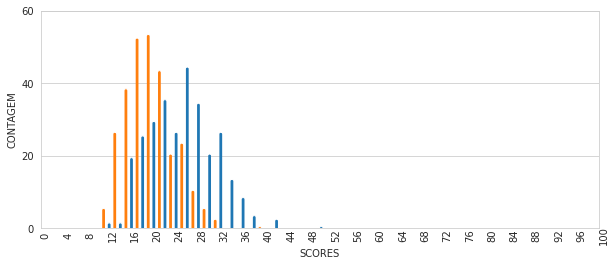

In [144]:
fig, ax = plt.subplots()
fig.set_size_inches(10,4)

plt.bar(wrst_txt_even.keys(), wrst_txt_even.values(), width=0.5, align='edge')
plt.bar(mean_txt_odd.keys(), mean_txt_odd.values(), width=0.5, align='edge')

from matplotlib.patches import FancyBboxPatch
new_patches = []
for patch in reversed(ax.patches):
    bb = patch.get_bbox()
    color=patch.get_facecolor()
    p_bbox = FancyBboxPatch((bb.xmin, bb.ymin-0.5),
                        abs(bb.width), abs(bb.height),
                        boxstyle="round,pad=-0.0020,rounding_size=0.5",
                        ec="none", fc=color,
                        mutation_aspect=1
                        )
    patch.remove()
    new_patches.append(p_bbox)
    
for patch in new_patches:
    ax.add_patch(patch)
    
abc = ax.get_xgridlines()
for i in abc:
    i.set_color(color='w')

ax.set_ylim(0, 60)
ax.set_xlabel('SCORES')
ax.set_ylabel('CONTAGEM')
ax.set_xticks(list(range(0,101,4)))
ax.set_yticks(list(range(0,61,20)))
plt.setp(ax.get_xticklabels(), rotation=90, ha="left", va="top", rotation_mode="anchor")


In [ ]:
from matplotlib.patches import FancyBboxPatch

def calc_histogram(self, gen_params, pred_results):
    fig, ax = plt.subplots()
    fig.set_size_inches(10,4)

    df_n_pg = pred_results[pred_results['y' == 0]]['score'].value_counts().sort_index().to_frame()
    df_n_pg.columns = ['score', 'count']
    
    df_pg = pred_results[pred_results['y' == 1]]['score'].value_counts().sort_index().to_frame()
    df_pg.columns = ['score', 'count']
    
    plt.bar(df_n_pg['score'], df_n_pg['count'], width=0.35, align='edge')
    plt.bar(df_pg['score'], df_pg['count'],, width=-0.35, align='edge')

    new_patches = []
    for patch in reversed(ax.patches):
        bb = patch.get_bbox()
        color=patch.get_facecolor()
        p_bbox = FancyBboxPatch((bb.xmin, bb.ymin-0.5),
                            abs(bb.width), abs(bb.height),
                            boxstyle="round,pad=-0.0020,rounding_size=0.5",
                            ec="none", fc=color,
                            mutation_aspect=1
                            )
        patch.remove()
        new_patches.append(p_bbox)

    for patch in new_patches:
        ax.add_patch(patch)

    for gridline in ax.get_xgridlines():
        gridline.set_color(color='w')

    max_y = max(df_n_pg['count'], df_pg['count'])
    ax.set_ylim(0, max_y + 0.2*max_y)
    ax.set_xlabel('SCORES')
    ax.set_ylabel('CONTAGEM')
    ax.set_xticks(list(range(0,101,4)))
    ax.set_yticks(list(range(0,61,20))) #3 quebras
    plt.setp(ax.get_xticklabels(), rotation=90, ha="center", va="top", rotation_mode="anchor")
    plt.savefig(gen_params['saving_path'] + pred_results['model'] + '_img_hist_score_dist_' + 
                str(gen_params['max_evals_hyper']) + gen_params['mdl_version'] + 
                gen_params['lead_domain'] + '.jpg')

In [ ]:
import matplotlib as mpl
mpl.style.use('seaborn') sns.set_style("whitegrid")

def calc_kde_intersec(self, gen_params, pred_results):
    #First histogram (equivalent to the one defined by calc_histogram())    
    fig1, ax1 = plt.subplots()
    fig1.set_size_inches(20, 8)
    sns.histplot(data=pred_results, x='score', hue='y_test', common_bins=True, palette=['red', 'dodgerblue'], ax=ax1, 
                 multiple='dodge', discrete=True, shrink=0.8)
    ax1.set_xlim([0, 100])
    filename = gen_params['saving_path'] + pred_results['model'] + '_img_hist_for_kde_' + 
                str(gen_params['max_evals_hyper']) + gen_params['mdl_version'] + 
                gen_params['lead_domain'] + '.jpg'
    plt.savefig(filename, dpi=300, bbox_inches='tight', pad_inches=0)
    
    #Plot KDE over histograms. Transform axes in densities
    fig2, ax2 = plt.subplots()
    sns.histplot (data=pred_results, x='score', hue='y_test', common_bins=True, palette=['red', 'dodgerblue'], kde=True, ax=ax2)
    ax2.set_xlim([0, 100])
    filename = gen_params['saving_path'] + pred_results['model'] + '_img_hist_kde_overlay_' + 
                str(gen_params['max_evals_hyper']) + gen_params['mdl_version'] + 
                gen_params['lead_domain'] + '.jpg'
    plt.savefig(filename, dpi=300, bbox_inches='tight', pad_inches=0)
    
    #Highlight areas of interest on the KDE plots
    fig3, ax3 = plt.subplots() #Experiment to choose the correct bandwith (bw_adjust=.25 or 2) 
    sns.kdeplot(data=pred_results, x='score', hue='y_test', palette=['red','dodgerblue'], ax=ax3, common_grid=True)
    mean_n_pg = np.mean(pred_results[pred_results['y_test'] == 0]['score'])
    mean_pg = np.mean(pred_results[pred_results['y_test'] == 1]['score'])
    dist_bt_means = mean_pg - mean_n_pg
    ax3.axvline(mean_n_pg, ls='--', color='black')
    ax3.axvline(mean_pg, ls='--', color='black')
    plt.annotate(s='', xy=(mean_n_pg,ax.get_ybound()*0.9), xytext=(mean_pg,ax.get_ybound()*0.9), arrowprops=dict(arrowstyle='<->'))
    ax3.set_xlim([0, 100])
    filename = gen_params['saving_path'] + pred_results['model'] + '_img_kde_annot_' + 
                str(gen_params['max_evals_hyper']) + gen_params['mdl_version'] + 
                gen_params['lead_domain'] + '.jpg'
    plt.savefig(filename, dpi=300, bbox_inches='tight', pad_inches=0)
    
    #Calculate intersection of the KDEs
    kde1, kde2 = ax3.get_lines()
    kde1_y = kde1.get_ydata()
    kde2_y = kde2.get_ydata()
    kde1_x = kde1.get_xdata() 
    kde2_x = kde2.get_xdata()
    xmin = min(kde1_x.min(), kde2_x.min())
    xmax = min(kde1_x.max(), kde2_x.max())
    dx = 0.2 * (xmax - xmin) # add a 20% margin, as the kde is wider than the data
    xmin -= dx
    xmax += dx
    x = np.linspace(xmin, xmax, len(kde1_x))
    
    inters_x = np.minimum(kde1_y, kde2_y)
    area_inters_x = np.trapz(inters_x, x)
    
    #Plot last viz
    fig4, (ax4_1, ax4_2) = plt.subplots(1,2)
    fig4.set_size(12, 8)
    ax4_1.plot(x, kde2_y, color='red', label='No')
    ax4_1.plot(x, kde1_y, color='dodgerblue', label='Yes')
    ax4_1.plot(x, inters_x, color='blueviolet')
    plt.fill_between(x, inters_x, 0, facecolor='none', edgecolor='blueviolet', hatch='xx', label='Intersecção')
    
    ax4_2.plot(x, inters_x, color='blueviolet')
    plt.fill_between(x, inters_x, 0, facecolor='none', edgecolor='blueviolet', hatch='xx', label='Intersecção')
    
    filename = gen_params['saving_path'] + pred_results['model'] + '_img_kde_intersec_area_' + 
                str(gen_params['max_evals_hyper']) + gen_params['mdl_version'] + 
                gen_params['lead_domain'] + '.jpg'
    plt.savefig(filename, dpi=300, bbox_inches='tight', pad_inches=0)
    plt.close()

In [ ]:
def summary_table(self, gen_params, pred_results):
    #Training and valid scores
    #Auc, f1, recall, prec
    #Prob calib
    #New metrics: KDE intersec and dist btw means